### E-Commerce Review Intelligence System

**MBA Business Analytics Assignment**  
**Dataset:** Amazon Fine Food Reviews

This notebook develops an end-to-end review intelligence workflow that translates unstructured customer feedback into actionable product and customer-experience insights.

#### Business Problem

E-commerce leaders receive thousands of product reviews, but manually reading them does not scale. The business needs a reliable way to identify how customers feel, understand the themes behind that feedback, and prioritize products where negative experiences create the greatest commercial risk.

**Decision question:** Which products and customer-experience themes should management investigate first to protect customer satisfaction and future revenue?



#### Dataset Description

This analysis uses the **Amazon Fine Food Reviews dataset.** Each record contains a product identifier, a 1-5 star rating, a review summary, and the full review text. Ratings provide a practical sentiment proxy: scores 1-2 are negative, 3 is neutral, and 4-5 are positive.



| # | Column | Description |
|---:|---|---|
| 1 | `Id` | Unique row or review identifier |
| 2 | `ProductId` | Unique identifier for the food or gourmet product |
| 3 | `UserId` | Unique identifier for the reviewer |
| 4 | `ProfileName` | Name or nickname of the reviewer |
| 5 | `HelpfulnessNumerator` | Number of users who found the review helpful |
| 6 | `HelpfulnessDenominator` | Total number of votes on whether the review was helpful |
| 7 | `Score` | Star rating from 1 to 5 |
| 8 | `Time` | Timestamp of the review |
| 9 | `Summary` | Short text summary or title of the review |
| 10 | `Text` | Full text content of the customer review |

In [1]:
# Experiment 2

# Text
#   ↓
# Tokenizer
#  ↓
# Integer sequences
#  ↓
# Embedding layer
#   ↓
#  LSTM
#   ↓
# Dense + Softmax
#     ↓
# Sentiment

In [2]:
# LSTM representation
#        ↓
#    Dense layer
#        ↓
#     Softmax
#        ↓
# Negative / Neutral / Positive

In [3]:
#                     RAW REVIEWS
#                          │
#                          ▼
#               ┌────────────────────┐
#               │ Exploratory Data   │
#               │ Analysis           │
#               └─────────┬──────────┘
#                         │
#                         ▼
#              Cleaning + Label Creation
#                         │
#               ┌─────────┴──────────┐
#               │                    │
#               ▼                    ▼
#       CLASSICAL NLP           TRANSFORMER
#               │                    │
#         TF-IDF / LSTM          Tokenizer
#           ┌───┴───┐                │
#           ▼       ▼                ▼
#      Logistic    Linear         DistilBERT
#      Regression   SVM               │
#           │       │                 │
#           └───────┴────────┬────────┘
#                            ▼
#                    MODEL EVALUATION
#                            │
#       ┌────────────────────┼──────────────────┐
#       ▼                    ▼                  ▼
#    Accuracy             Macro F1        Confusion Matrix
#                            │
#                            ▼
#                      ERROR ANALYSIS
#                            │
#                            ▼
#                       BEST MODEL
#                            │
#                            ▼
#                        BERTopic
#                            │
#                            ▼
#                 TOPIC × SENTIMENT
#                            │
#                            ▼
#                    BUSINESS INSIGHTS
#                            │
#                ┌───────────┼────────────┐
#                ▼           ▼            ▼
#              Product     Marketing     Service
#            Improvement    Insights    Improvement

1. Importing Libraries

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [6]:
import tensorflow as tf

# Tokenizers convert Inputs into Integer sequences
from tensorflow.keras.preprocessing.text import Tokenizer
# Padding ensures all sequences have the same length
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, # Converts word id's into trainable dense vectors
    LSTM, # Processes vectors sequentially
    Dense, # Final Neural Network Classifier
    Dropout # Helps reduce overfitting
)
from tensorflow.keras.callbacks import (
    EarlyStopping, # Stops training when a monitored metric has stopped improving
    ModelCheckpoint # Saves the model after every epoch if it has improved
)

In [7]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

2. Importing Datasets

In [8]:
df = pd.read_csv("./Reviews.csv")

In [9]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


Rows: 568454, Columns: 10


3. Examining Dataset

In [10]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [11]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


Missing Values

In [13]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [14]:
df = df.dropna(subset=["Summary"])
df = df.reset_index(drop=True)

In [15]:
print("Total duplicated rows in the dataframe:", df.duplicated().sum())

Total duplicated rows in the dataframe: 0


In [16]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29744
3     42638
4     80655
5    363122
Name: count, dtype: int64

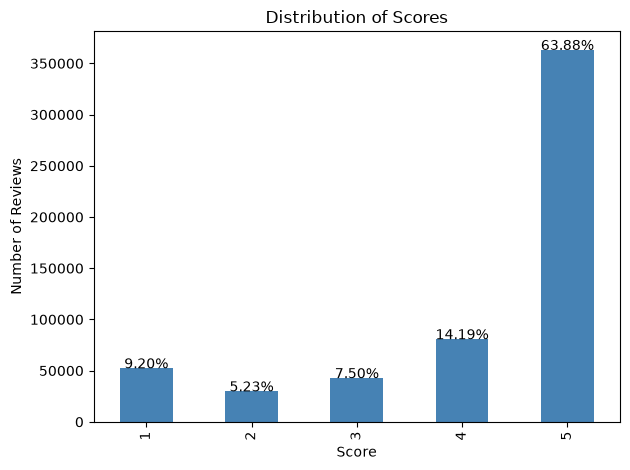

In [17]:
# Plot the distribution of review scores
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Score"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

4. Convert Rating into Sentiment
* [1, 2] -> Negative
* [ 3  ]    -> Neutral
* [4, 5] -> Positive

In [18]:
def create_sentiment(score: int) -> str:
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

In [19]:
df["Sentiment"] = df["Score"].apply(create_sentiment)

In [20]:
df[["Score", "Sentiment"]].head(10)

,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive
5,4,Positive
6,5,Positive
7,5,Positive
8,5,Positive
9,5,Positive


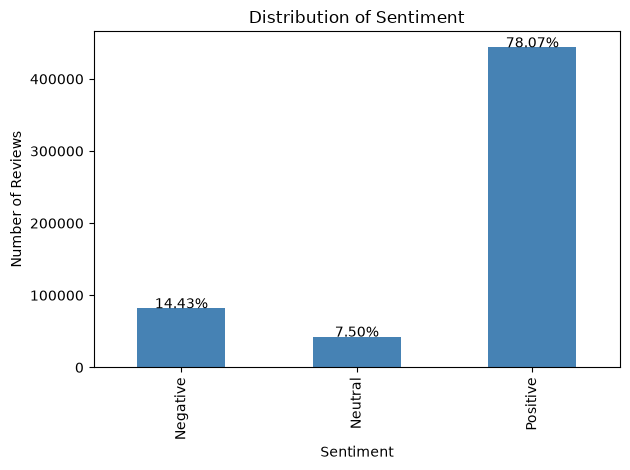

In [21]:
# Plot the distribution of Sentiment
df["Sentiment"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Sentiment"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )


plt.title("Distribution of Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Inference: Class Highly Imbalanced -
* Positive - 78 %
* Neutral - 7.5%
* Negative - 14.5 %

Merging Summary with Text in Review Column appended by comma(',')

In [22]:
df["Review"] = (df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
df["Review"].head()

0    Good Quality Dog Food , I have bought several ...
1    Not as Advertised , Product arrived labeled as...
2    "Delight" says it all , This is a confection t...
3    Cough Medicine , If you are looking for the se...
4    Great taffy , Great taffy at a great price.  T...
Name: Review, dtype: str

5. Basic Text Preprocessing

In [23]:
import re

In [24]:
def clean_text_lstm(text: str) -> str:
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URL's
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize repeated whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [25]:
df["Clean_Review"] = df["Review"].apply(clean_text_lstm)

In [26]:
print(df["Review"].iloc[-5])
print("----------")
print(df["Clean_Review"].iloc[-5])

Will not do without , Great for sesame chicken..this is a good if not better than resturants I have eaten at..My husband loved it..will find other recipes to use this in..
----------
will not do without , great for sesame chicken..this is a good if not better than resturants i have eaten at..my husband loved it..will find other recipes to use this in..


* Inference : Stopwords should not be removed as it will remove the sentiment in the review comments

In [27]:
# TensorFlow works more naturally with numeric classes.
label_map = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

In [28]:
df["Label"] = df["Sentiment"].map(label_map)

In [29]:
df[["Sentiment", "Label"]].head()

,Sentiment,Label
0,Positive,2
1,Negative,0
2,Positive,2
3,Negative,0
4,Positive,2


In [30]:
X = df["Clean_Review"] # Actual Review
y = df["Label"] # Sentiment Class Label

6. Train / Validation / Test Split

* 70% training
* 15% validation
* 15% testing

Experiment 1: TF-IDF + Logistic Regression

In [31]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=SEED,
    stratify=y # tries to preserve a similar sentiment distribution in the splits.
)

In [32]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp # tries to preserve a similar sentiment distribution in the splits.
)

In [33]:
print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 397898
Validation set size: 85264
Test set size: 85265


#### 7. Analysing Review Length for choosing LSTM length


In [34]:
review_lengths = X_train.str.split().str.len()

In [35]:
review_lengths.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

count    397898.000000
mean         84.823070
std          79.221449
min           5.000000
50%          61.000000
75%         103.000000
90%         166.000000
95%         223.000000
99%         392.000000
max        3429.000000
Name: Clean_Review, dtype: float64

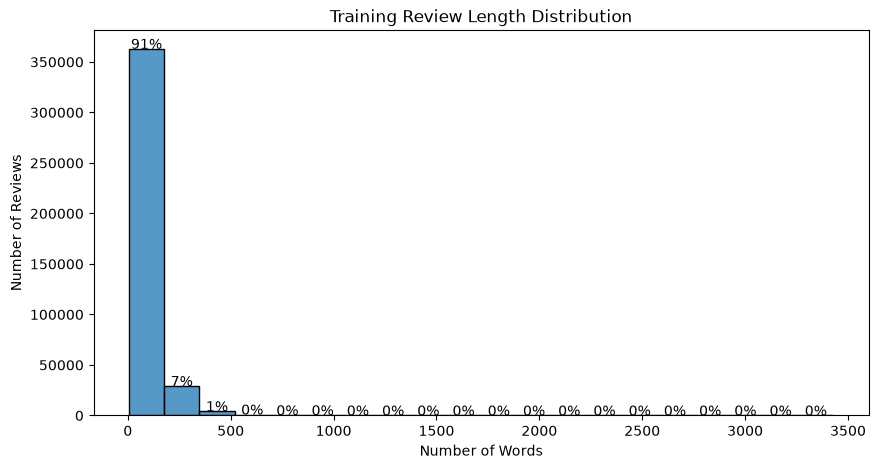

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    review_lengths,
    bins=20
)

# Show percentage on the bars
total = len(review_lengths)
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.0f}%'.format(100 * height / total),
        ha="center"
    )

plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("Training Review Length Distribution")

plt.show()

> Inference: 95% of the Reviews lies inside 225 words limit

In [37]:
MAX_LENGTH = 225

Create the Vocabulary

In [38]:
VOCAB_SIZE = 30000

### Tokenization 
> Tokenizer learns Vocabulary

In [39]:
tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

OOV = Out Of Vocabulary.

In [40]:
tokenizer.fit_on_texts(X_train)

In [41]:
list(tokenizer.word_index.items())[:20]

[('<OOV>', 1),
 ('the', 2),
 ('i', 3),
 ('and', 4),
 ('a', 5),
 ('to', 6),
 ('it', 7),
 ('of', 8),
 ('is', 9),
 ('this', 10),
 ('for', 11),
 ('in', 12),
 ('my', 13),
 ('that', 14),
 ('but', 15),
 ('not', 16),
 ('with', 17),
 ('have', 18),
 ('you', 19),
 ('are', 20)]

Convert Sentences into Sequences

In [42]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [43]:
print(X_train.iloc[0])
print("---------- -------- -------")
print(X_train_seq[0])

great gum! , i love this gum, it has a great burst of flavor and a really cool-mouth feeling (even the fruit flavored)! the only draw back is that the flavor runs out quickly...but knowing that i'm chewing something actually good for me wins the battle for me.
---------- -------- -------
[29, 624, 3, 44, 10, 624, 7, 53, 5, 29, 3229, 8, 42, 4, 5, 63, 1071, 478, 925, 91, 2, 309, 322, 2, 68, 4302, 205, 9, 14, 2, 42, 1843, 58, 452, 15, 1546, 14, 93, 991, 173, 258, 27, 11, 51, 5520, 2, 5997, 11, 51]


Padding - Consistent Shapes in Neural Network Batches

In [44]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding='post', # padding zeros after the sequence till MAX_LENGTH
    truncating='post' # stripping last elements if sequence is longer than MAX_LENGTH
)
X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LENGTH,
    padding='post', # padding zeros after the sequence till MAX_LENGTH
    truncating='post' # stripping last elements if sequence is longer than MAX_LENGTH
)
X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding='post', # padding zeros after the sequence till MAX_LENGTH
    truncating='post' # stripping last elements if sequence is longer than MAX_LENGTH
)

In [45]:
print(X_train_pad.shape)

(397898, 225)


#### Building Embedding + LSTM 

In [46]:
EMBEDDING_DIM = 128
LSTM_UNITS = 64
NUM_CLASSES = 3

In [47]:
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True # this tells dont consider padding (0) in the sequence
    ),
    LSTM(
        LSTM_UNITS
    ),
    Dropout(0.3), # During training 30% of the neurons will be randomly dropped to prevent overfitting
    Dense(
        32,
        activation='relu'
    ),
    Dropout(0.3), # During training 30% of the neurons will be randomly dropped to prevent overfitting
    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [48]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # because we have 3 different classes
    metrics=['accuracy']
)

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [52]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, weights)
)


In [53]:
class_weights

{np.int64(0): np.float64(2.310351635079896),
 np.int64(1): np.float64(4.443752024212372),
 np.int64(2): np.float64(0.4269617106024171)}

In [54]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2, # if validation loss stops improving for 2 epochs, stop training
    restore_best_weights=True, # restore the model weights from the epoch with the best validation loss
)

In [55]:
checkpoint = ModelCheckpoint(
    "best_lstm.keras",
    monitor='val_loss', # monitor the validation loss
    save_best_only=True, # save only the model with the best validation loss
)

In [56]:
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(
        X_val_pad,
        y_val
    ),
    epochs=10,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 575s 92ms/step - accuracy: 0.7546 - loss: 0.7379 - val_accuracy: 0.7669 - val_loss: 0.5172
Epoch 2/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 571s 92ms/step - accuracy: 0.8292 - loss: 0.5309 - val_accuracy: 0.8023 - val_loss: 0.4886
Epoch 3/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 569s 92ms/step - accuracy: 0.8677 - loss: 0.4296 - val_accuracy: 0.8665 - val_loss: 0.3590
Epoch 4/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 575s 92ms/step - accuracy: 0.8917 - loss: 0.3478 - val_accuracy: 0.8841 - val_loss: 0.3400
Epoch 5/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 571s 92ms/step - accuracy: 0.9099 - loss: 0.2832 - val_accuracy: 0.8811 - val_loss: 0.3664
Epoch 6/10
6218/6218 ━━━━━━━━━━━━━━━━━━━━ 557s 90ms/step - accuracy: 0.9237 - loss: 0.2350 - val_accuracy: 0.8929 - val_loss: 0.3528


Visualise Training

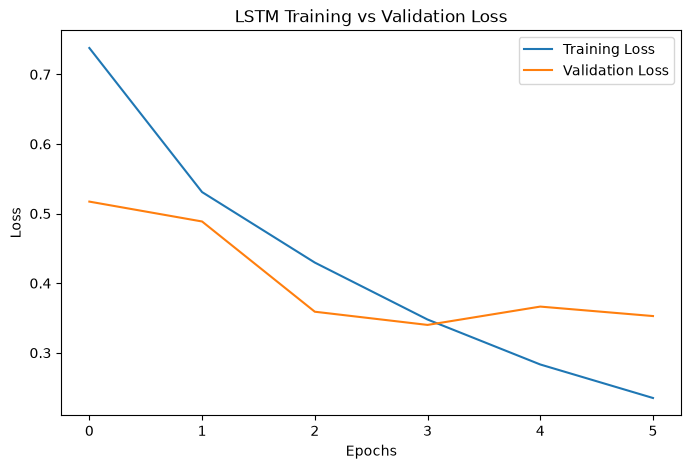

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.show()

Visualise Accuracy

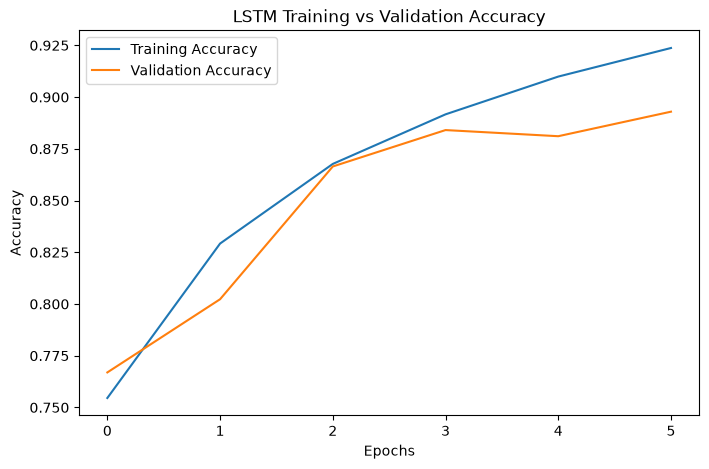

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("LSTM Training vs Validation Accuracy")
plt.legend()
plt.show()


In [59]:
y_prob = model.predict(
    X_test_pad
)

2665/2665 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step


In [60]:
y_pred = np.argmax(
    y_prob,
    axis=1
)

Model Evaluation

In [61]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

In [62]:


print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))


Accuracy: 0.8858
Precision: 0.743
Recall: 0.8232
F1 Score: 0.7685


In [63]:
target_names = [
    "Negative",
    "Neutral",
    "Positive"
]


Classification Report

In [64]:
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
))

              precision    recall  f1-score   support

    Negative     0.8247    0.8209    0.8228     12302
     Neutral     0.4231    0.7366    0.5374      6396
    Positive     0.9812    0.9121    0.9454     66567

    accuracy                         0.8858     85265
   macro avg     0.7430    0.8232    0.7685     85265
weighted avg     0.9167    0.8858    0.8971     85265



Confusion Matrix

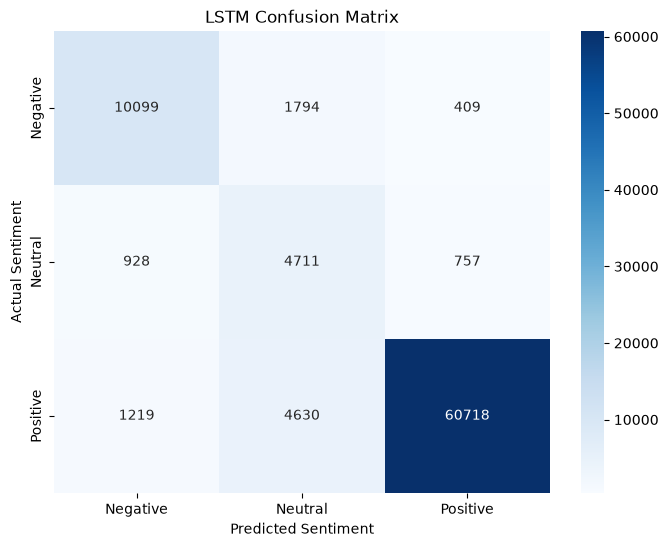

In [65]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Confusion Matrix")

plt.show()

In [66]:
results = pd.DataFrame({
    "Review": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Confidence": np.max(y_prob, axis=1)
})

In [69]:
reverse_label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

results["Actual"] = (
    results["Actual"]
    .map(reverse_label_map)
)

results["Predicted"] = (
    results["Predicted"]
    .map(reverse_label_map)
)

In [70]:
error = results[
    results["Actual"] != results["Predicted"]
]

In [71]:
error.sort_values(
    by="Confidence",
    ascending=False
).head(20)

,Review,Actual,Predicted,Confidence
21959,"nutro natural choice senior chicken and rice ,...",Negative,Positive,0.999903
61440,handy. tasty. high on sodium. low on protein. ...,Neutral,Positive,0.999898
40101,popular company is edging out the nut free com...,Negative,Positive,0.999882
36308,"4 for one...its a toss up. , there are few pla...",Neutral,Positive,0.999876
23133,"the only flavor we both don't like... , love t...",Neutral,Positive,0.999873
28151,"greatest pretzels ever! , this took way too lo...",Neutral,Positive,0.999863
76556,"good tea , arrives quickly great price and i d...",Neutral,Positive,0.999856
57836,"dogs love these bones , my dog loves these bon...",Neutral,Positive,0.999852
84877,"dogs love these bones , my dog loves these bon...",Neutral,Positive,0.999852
21322,"subtle flavour, very subtle , this gouda chees...",Neutral,Positive,0.999824


In [72]:
def predict_sentiment(review: str):
    review = clean_text_lstm(review)
    sequence = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding='post',
        truncating='post'
    )

    probabilities = model.predict(
        padded,
        verbose=0
    )[0]

    predicted_class = np.argmax(
        probabilities
    )

    return {
        "sentiment": reverse_label_map[predicted_class],
        "confidence": float(probabilities[predicted_class]),
        "probabilities": {
            "Negative": float(probabilities[0]),
            "Neutral": float(probabilities[1]),
            "Positive": float(probabilities[2])
        }
    }

In [73]:
predict_sentiment("This tasted horrible and I will never buy it again")

{'sentiment': 'Negative',
 'confidence': 0.9974289536476135,
 'probabilities': {'Negative': 0.9974289536476135,
  'Neutral': 0.002306191483512521,
  'Positive': 0.000264826841885224}}

In [75]:
predict_sentiment(
    "The taste is excellent but the packaging was terrible"
)

{'sentiment': 'Neutral',
 'confidence': 0.5270776152610779,
 'probabilities': {'Negative': 0.4619227349758148,
  'Neutral': 0.5270776152610779,
  'Positive': 0.010999677702784538}}

In [76]:
embedding_layer = model.layers[0]

embedding_weights = (
    embedding_layer.get_weights()[0]
)

In [77]:
print(embedding_weights.shape)

(30000, 128)


VOCAB_SIZE X EMBEDDING_DIM

In [78]:
model.save("lstm_sentiment_model.keras")

In [79]:
import pickle

In [80]:
with open("lstm_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

In [82]:
config = {
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "max_length": MAX_LENGTH,
    "lstm_units": LSTM_UNITS,
    "label_map": label_map
}

(config)

{'vocab_size': 30000,
 'embedding_dim': 128,
 'max_length': 225,
 'lstm_units': 64,
 'label_map': {'Negative': 0, 'Neutral': 1, 'Positive': 2}}

In [84]:
experiment_2_results = {
    "Model": "Embedding + LSTM",
    "Accuracy": round(accuracy*100, 4),
    "Macro Precision": round(precision*100, 4),
    "Macro Recall": round(recall*100, 4),
    "Macro F1": round(f1*100, 4)
}

experiment_2_results

{'Model': 'Embedding + LSTM',
 'Accuracy': 88.5803,
 'Macro Precision': 74.2972,
 'Macro Recall': 82.3204,
 'Macro F1': 76.8544}